## Clasificación de sentimientos de reseñas de IMDb con RNN

Objetivo: clasificar reseñas de películas de IMDb como positivas o negativas.

Pipeline:
1. Limpieza y tokenización del texto.
2. Paso a secuencias numéricas, con embeddings GloVe preentrenados (100 dimensiones).
3. Entrenamiento de dos redes recurrentes bidireccionales: BiLSTM y BiGRU.

Cada modelo se entrena con 3 semillas. En prueba se reportan exactitud, precisión, recall y F1 como media ± desviación estándar.

### 1. Configuración y datos

In [1]:
#!pip -q install gensim kagglehub

In [2]:
import os, re, glob, copy, random, shutil
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')   # GPU de Apple Silicon
else:
    device = torch.device('cpu')
print('Dispositivo:', device)

FIG_DIR = './resultados'
os.makedirs(FIG_DIR, exist_ok=True)

CLASES = ['negativa', 'positiva']   # label 0 / 1
MAX_LEN = 256        # palabras máximas por reseña (se trunca el resto)
VOCAB_SIZE = 20000   # palabras más frecuentes de train


def fijar_semilla(s):
    """Hace reproducibles los experimentos."""
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

Dispositivo: mps


In [3]:
import kagglehub

DATA_DIR = kagglehub.dataset_download('yasserh/imdb-movie-ratings-sentiment-analysis')
csvs = glob.glob(os.path.join(DATA_DIR, '**', '*.csv'), recursive=True)
print('Archivos CSV:', csvs)

df = pd.read_csv(csvs[0])
assert {'text', 'label'} <= set(df.columns), f'Columnas inesperadas: {list(df.columns)}'
df = df[['text', 'label']].dropna()
df['label'] = df['label'].astype(int)
print('Reseñas:', len(df))
df.head()

/Users/alejandrosanabria/Documents/Uniandes/MAIA/22 - Técnicas de Deep Learning/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Archivos CSV: ['/Users/alejandrosanabria/.cache/kagglehub/datasets/yasserh/imdb-movie-ratings-sentiment-analysis/versions/1/movie.csv']
Reseñas: 40000


,text,label
0,I grew up (b. 1965) watching and loving the Th...,0
1,"When I put this movie in my DVD player, and sa...",0
2,Why do people who do not know what a particula...,0
3,Even though I have great interest in Biblical ...,0
4,Im a die hard Dads Army fan and nothing will e...,1


### 2. Exploración
Se revisa el balance de clases y la longitud de las reseñas. Con la longitud se elige `MAX_LEN`.

count    40000.0
mean       231.0
std        171.0
min          4.0
50%        173.0
75%        282.0
90%        452.0
max       2470.0
Name: n_palabras, dtype: float64
Reseñas con <= 256 palabras: 71.2%


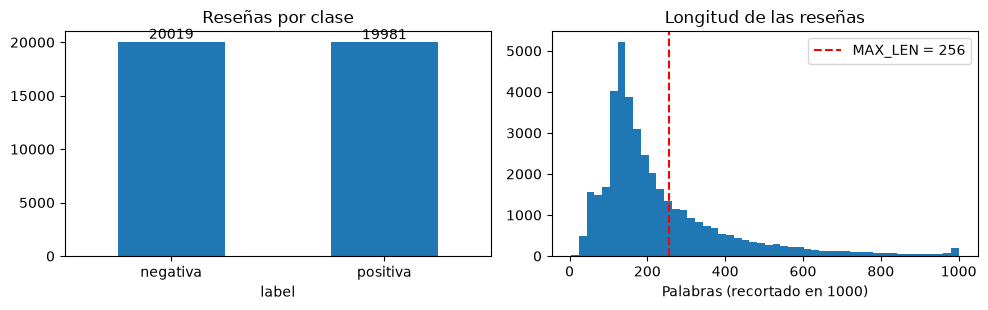

In [4]:
df['n_palabras'] = df['text'].str.split().str.len()
print(df['n_palabras'].describe(percentiles=[0.5, 0.75, 0.9]).round(0))
print(f'Reseñas con <= {MAX_LEN} palabras: {(df["n_palabras"] <= MAX_LEN).mean():.1%}')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
conteo = df['label'].map(dict(enumerate(CLASES))).value_counts().reindex(CLASES)
conteo.plot.bar(ax=axes[0], rot=0, title='Reseñas por clase')
axes[0].bar_label(axes[0].containers[0])
axes[1].hist(df['n_palabras'].clip(upper=1000), bins=50)
axes[1].axvline(MAX_LEN, color='red', ls='--', label=f'MAX_LEN = {MAX_LEN}')
axes[1].set(title='Longitud de las reseñas', xlabel='Palabras (recortado en 1000)')
axes[1].legend()
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/exploracion.png', dpi=300)
plt.show()

### 3. Limpieza y división
- Limpieza: minúsculas, se quitan las etiquetas HTML (`<br />`) y se conservan solo letras. Las contracciones se separan igual que en GloVe (`don't` → `do n't`, `it's` → `it 's`).
- Duplicados: hay reseñas repetidas. Si una copia queda en train y otra en test, las métricas salen infladas. Por eso se deja una copia por texto y se eliminan los textos que aparecen con etiquetas distintas.
- División: estratificada, 70 % train / 15 % validación / 15 % prueba.

In [5]:
def limpiar(texto):
    """Texto crudo -> lista de tokens."""
    texto = texto.lower()
    texto = re.sub(r'<[^>]+>', ' ', texto)        # etiquetas HTML
    texto = re.sub(r"n't\b", " n't", texto)       # don't -> do n't
    return re.findall(r"n't|[a-z]+|'[a-z]+", texto)


print(limpiar("I didn't like it.<br /><br />It's TOO long!!"))

df['limpio'] = [' '.join(limpiar(t)) for t in df['text']]
df = df[df['limpio'].str.len() > 0]

conflicto = df.groupby('limpio')['label'].transform('nunique') > 1   # mismo texto, distinta etiqueta
df_limpio = df[~conflicto].drop_duplicates('limpio').reset_index(drop=True)
print(f'Originales: {len(df)} | en conflicto: {conflicto.sum()} | finales: {len(df_limpio)}')

df_train, df_temp = train_test_split(df_limpio, test_size=0.3, stratify=df_limpio['label'], random_state=42)
df_val, df_test = train_test_split(df_temp, test_size=0.5, stratify=df_temp['label'], random_state=42)

pd.DataFrame({'train': df_train['label'].value_counts(),
              'val': df_val['label'].value_counts(),
              'test': df_test['label'].value_counts()}).rename(index=dict(enumerate(CLASES)))

['i', 'did', "n't", 'like', 'it', 'it', "'s", 'too', 'long']
Originales: 40000 | en conflicto: 0 | finales: 39720


,train,val,test
label,,,
positiva,13935,2986,2986
negativa,13869,2972,2972


### 4. Vocabulario, embeddings GloVe y secuencias
- El vocabulario se construye solo con train, para no filtrar información de validación ni de prueba. Tiene las `VOCAB_SIZE` palabras más frecuentes más dos índices especiales: `<pad>` = 0 (relleno) y `<unk>` = 1 (palabra desconocida).
- Embeddings: cada palabra del vocabulario toma su vector GloVe de 100 dimensiones (Wikipedia + Gigaword). Las que no están en GloVe reciben un vector aleatorio pequeño y `<pad>` queda en cero.
- Secuencias: cada reseña se convierte en una lista de índices, se trunca a `MAX_LEN` y se rellena con ceros al final. Se guarda también la longitud real de cada reseña para que la RNN ignore el relleno.

In [6]:
frecuencias = Counter(w for t in df_train['limpio'] for w in t.split())
itos = ['<pad>', '<unk>'] + [w for w, _ in frecuencias.most_common(VOCAB_SIZE)]
stoi = {w: i for i, w in enumerate(itos)}
print('Tamaño del vocabulario:', len(itos))

Tamaño del vocabulario: 20002


In [7]:
import gensim.downloader

glove = gensim.downloader.load('glove-wiki-gigaword-100')   # ~128 MB
EMB_DIM = glove.vector_size

rng = np.random.default_rng(0)
E = rng.normal(0, 0.1, (len(itos), EMB_DIM)).astype('float32')
E[0] = 0   # <pad>
en_glove = 0
for i, w in enumerate(itos[2:], start=2):
    if w in glove.key_to_index:
        E[i] = glove[w]
        en_glove += 1

tokens_train = sum(frecuencias[w] for w in itos[2:])
tokens_glove = sum(frecuencias[w] for w in itos[2:] if w in glove.key_to_index)
print(f'Palabras del vocabulario con vector GloVe: {en_glove / (len(itos) - 2):.1%}')
print(f'Tokens de train cubiertos por GloVe: {tokens_glove / tokens_train:.1%}')
del glove   # libera memoria

Palabras del vocabulario con vector GloVe: 99.1%
Tokens de train cubiertos por GloVe: 99.9%


In [8]:
def codificar(texto_limpio):
    """Texto limpio -> lista de índices (máximo MAX_LEN)."""
    ids = [stoi.get(w, 1) for w in texto_limpio.split()]
    if len(ids) > MAX_LEN:
        ids = ids[:MAX_LEN // 2] + ids[-MAX_LEN // 2:]   # primeras 128 + últimas 128 palabras
    return ids or [1]


def a_dataset(tabla):
    """Devuelve un TensorDataset con (secuencias con padding, longitudes, etiquetas)."""
    seqs = [codificar(t) for t in tabla['limpio']]
    X = torch.zeros(len(seqs), MAX_LEN, dtype=torch.long)
    for i, s in enumerate(seqs):
        X[i, :len(s)] = torch.tensor(s)
    largos = torch.tensor([len(s) for s in seqs])
    y = torch.tensor(tabla['label'].values, dtype=torch.float32)
    return TensorDataset(X, largos, y)


ds_train, ds_val, ds_test = a_dataset(df_train), a_dataset(df_val), a_dataset(df_test)
loader_val = DataLoader(ds_val, batch_size=256)
loader_test = DataLoader(ds_test, batch_size=256)

x0, l0, y0 = ds_train[0]
print('Reseña:', df_train['limpio'].iloc[0][:150], '...')
print('Índices:', x0[:15].tolist(), '| largo:', l0.item(), '| etiqueta:', CLASES[int(y0)])

Reseña: this film did well at the box office and the producers of this mess thought the stars had such good chemistry in this that they cast them in the much  ...
Índices: [11, 20, 71, 74, 32, 2, 844, 1022, 3, 2, 1145, 5, 11, 974, 186] | largo: 130 | etiqueta: negativa


### 5. Modelo
Se usa una sola clase, `RNNClasificador`, que cambia la capa recurrente entre LSTM y GRU:

- Embedding (20 002 × 100, GloVe, ajustable): convierte índices en vectores densos con semántica previa y se adapta al vocabulario de cine.
- Dropout (0.3): regulariza los embeddings y reduce el sobreajuste a palabras concretas.
- LSTM / GRU bidireccional (1 capa, 128 unidades por dirección): lee la reseña en ambos sentidos para captar contexto como negaciones. Sus compuertas mitigan el desvanecimiento del gradiente y `pack_padded_sequence` evita que el relleno afecte el estado final.
- Concatenación + Dropout (256, 0.3): une los estados finales forward y backward en un resumen de la reseña.
- Densa + sigmoide (256 → 1): da la probabilidad de reseña positiva. En entrenamiento la sigmoide va dentro de `BCEWithLogitsLoss` por estabilidad numérica y al predecir se aplica de forma explícita.

In [9]:
class RNNClasificador(nn.Module):
    def __init__(self, tipo, embeddings, hidden=128, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding.from_pretrained(torch.tensor(embeddings), freeze=False, padding_idx=0)
        self.drop = nn.Dropout(dropout)
        RNN = nn.LSTM if tipo == 'lstm' else nn.GRU
        self.rnn = RNN(embeddings.shape[1], hidden, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(2 * hidden, 1)

    def forward(self, x, largos):
        e = self.drop(self.emb(x))
        e = pack_padded_sequence(e, largos.cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.rnn(e)
        if isinstance(h, tuple):   # la LSTM devuelve (h, c)
            h = h[0]
        h = torch.cat([h[-2], h[-1]], dim=1)   # último estado forward y backward
        return self.fc(self.drop(h)).squeeze(1)   # logit; sigmoide -> probabilidad de 'positiva'


CONFIGS = {'BiLSTM': 'lstm', 'BiGRU': 'gru'}
for nombre, tipo in CONFIGS.items():
    print(f'{nombre}: {sum(p.numel() for p in RNNClasificador(tipo, E).parameters()):,} parámetros')

BiLSTM: 2,235,977 parámetros
BiGRU: 2,177,097 parámetros


### 6. Entrenamiento
Adam (lr 1e-3), batch de 64 y pérdida de entropía cruzada binaria (`BCEWithLogitsLoss`). El gradiente se recorta a norma 1.0 (gradient clipping). Se entrena hasta 8 épocas con early stopping sobre la pérdida de validación y se conservan los pesos de la mejor época.

In [10]:
def correr_epoca(modelo, loader, criterio, optimizador=None):
    """Una pasada por el loader: entrena si recibe optimizador, si no solo evalúa. Devuelve (pérdida, exactitud)."""
    entrenar = optimizador is not None
    modelo.train(entrenar)
    perdida, aciertos = 0.0, 0
    with torch.set_grad_enabled(entrenar):
        for x, largos, y in loader:
            x, y = x.to(device), y.to(device)
            logits = modelo(x, largos)
            loss = criterio(logits, y)
            if entrenar:
                optimizador.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
                optimizador.step()
            perdida += loss.item() * len(y)
            aciertos += ((logits > 0).float() == y).sum().item()
    n = len(loader.dataset)
    return perdida / n, aciertos / n


def entrenar(modelo, loader_train, epocas=8, lr=1e-3, paciencia=2):
    """Entrena con early stopping y deja en el modelo los pesos de la mejor época de validación."""
    criterio = nn.BCEWithLogitsLoss()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc']}
    mejor, mejores_pesos, sin_mejora = float('inf'), None, 0
    for ep in range(1, epocas + 1):
        tl, ta = correr_epoca(modelo, loader_train, criterio, optimizador)
        vl, va = correr_epoca(modelo, loader_val, criterio)
        for k, v in zip(hist, [tl, ta, vl, va]):
            hist[k].append(v)
        print(f'  época {ep:2d} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}')
        if vl < mejor:
            mejor, mejores_pesos, sin_mejora = vl, copy.deepcopy(modelo.state_dict()), 0
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                print('  early stopping')
                break
    modelo.load_state_dict(mejores_pesos)
    return hist


@torch.no_grad()
def predecir(modelo, loader):
    """Devuelve (y_true, y_pred, probabilidad de 'positiva')."""
    modelo.eval()
    probs = torch.cat([torch.sigmoid(modelo(x.to(device), l)).cpu() for x, l, _ in loader]).numpy()
    y_true = loader.dataset.tensors[2].numpy().astype(int)
    return y_true, (probs > 0.5).astype(int), probs

In [11]:
SEMILLAS = [0, 1, 2]

corridas = []   # una por (modelo, semilla)
modelos = {}    # modelos de la semilla 0, para el análisis cualitativo
for nombre, tipo in CONFIGS.items():
    for s in SEMILLAS:
        print(f'=== {nombre} | semilla {s} ===')
        fijar_semilla(s)
        loader_train = DataLoader(ds_train, batch_size=64, shuffle=True)
        modelo = RNNClasificador(tipo, E).to(device)
        hist = entrenar(modelo, loader_train)

        y_true, y_pred, probs = predecir(modelo, loader_test)
        metricas = {'acc': accuracy_score(y_true, y_pred), 'precision': precision_score(y_true, y_pred),
                    'recall': recall_score(y_true, y_pred), 'f1': f1_score(y_true, y_pred)}
        print('  -> test ' + ' | '.join(f'{k} {v:.4f}' for k, v in metricas.items()) + '\n')

        corridas.append({'modelo': nombre, 'semilla': s, 'hist': hist, **metricas,
                         'y_true': y_true, 'y_pred': y_pred, 'probs': probs})
        if s == 0:
            modelos[nombre] = modelo

=== BiLSTM | semilla 0 ===
  época  1 | train loss 0.5389 acc 0.7292 | val loss 0.3890 acc 0.8437
  época  2 | train loss 0.3342 acc 0.8584 | val loss 0.3313 acc 0.8562
  época  3 | train loss 0.2368 acc 0.9067 | val loss 0.2521 acc 0.9023
  época  4 | train loss 0.1790 acc 0.9332 | val loss 0.2671 acc 0.9025
  época  5 | train loss 0.1374 acc 0.9506 | val loss 0.2758 acc 0.9011
  early stopping
  -> test acc 0.8844 | precision 0.9068 | recall 0.8573 | f1 0.8814

=== BiLSTM | semilla 1 ===
  época  1 | train loss 0.5627 acc 0.7071 | val loss 0.4308 acc 0.8204
  época  2 | train loss 0.3314 acc 0.8636 | val loss 0.2840 acc 0.8896
  época  3 | train loss 0.2329 acc 0.9106 | val loss 0.2449 acc 0.9011
  época  4 | train loss 0.1809 acc 0.9326 | val loss 0.2789 acc 0.8949
  época  5 | train loss 0.1380 acc 0.9518 | val loss 0.2915 acc 0.8991
  early stopping
  -> test acc 0.8879 | precision 0.8988 | recall 0.8747 | f1 0.8866

=== BiLSTM | semilla 2 ===
  época  1 | train loss 0.5448 acc 0.

### 7. Resultados cuantitativos
Métricas en prueba (%), como media ± desviación estándar de las 3 semillas. Precisión, recall y F1 se calculan sobre la clase positiva.

In [12]:
res = pd.DataFrame(corridas)
tabla = res.groupby('modelo')[['acc', 'precision', 'recall', 'f1']].agg(['mean', 'std']).mul(100).round(2)
tabla.to_csv(f'{FIG_DIR}/tabla_resultados.csv')
tabla

acc       precision       recall           f1      
         mean   std      mean   std   mean   std   mean   std
modelo                                                       
BiGRU   89.33  0.41     89.14  1.96  89.70  1.88  89.39  0.32
BiLSTM  88.45  0.33     89.49  1.44  87.24  1.40  88.33  0.29

In [13]:
# Precisión, recall y F1 por clase (semilla 0)
for c in corridas:
    if c['semilla'] == 0:
        print(f'===== {c["modelo"]} =====')
        print(classification_report(c['y_true'], c['y_pred'], target_names=CLASES, digits=4))

===== BiLSTM =====
              precision    recall  f1-score   support

    negativa     0.8641    0.9115    0.8872      2972
    positiva     0.9068    0.8573    0.8814      2986

    accuracy                         0.8844      5958
   macro avg     0.8855    0.8844    0.8843      5958
weighted avg     0.8855    0.8844    0.8843      5958

===== BiGRU =====
              precision    recall  f1-score   support

    negativa     0.8799    0.9169    0.8980      2972
    positiva     0.9137    0.8754    0.8941      2986

    accuracy                         0.8961      5958
   macro avg     0.8968    0.8962    0.8961      5958
weighted avg     0.8968    0.8961    0.8961      5958



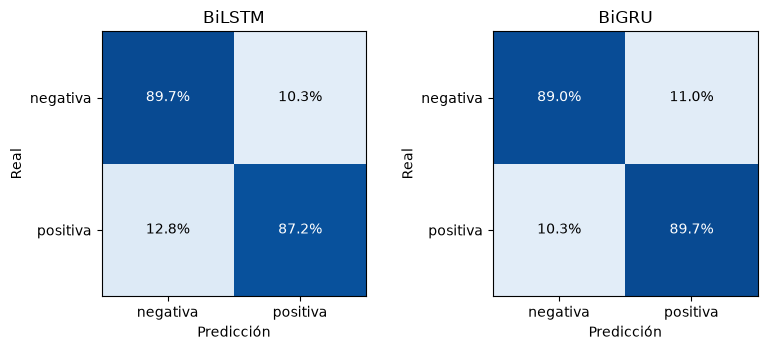

In [14]:
# Matrices de confusión: suma de las 3 semillas, normalizada por fila (%)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
for ax, nombre in zip(axes, CONFIGS):
    cm = sum(confusion_matrix(c['y_true'], c['y_pred']) for c in corridas if c['modelo'] == nombre)
    cm = cm / cm.sum(axis=1, keepdims=True) * 100
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]:.1f}%', ha='center', va='center', color='white' if cm[i, j] > 50 else 'black')
    ax.set(xticks=range(2), yticks=range(2), xticklabels=CLASES, yticklabels=CLASES,
           title=nombre, xlabel='Predicción', ylabel='Real')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/matrices_confusion.png', dpi=300)
plt.show()

### 8. Resultados cualitativos
#### 8.1 Curvas de aprendizaje (semilla 0)
Línea continua: entrenamiento. Línea discontinua: validación.

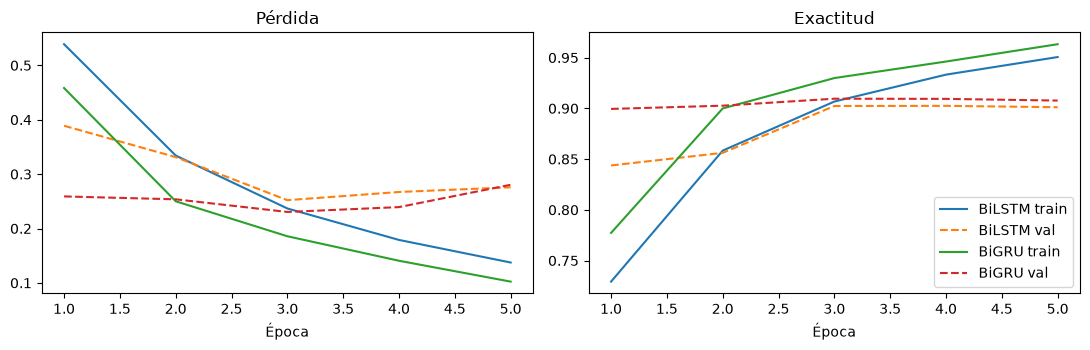

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for c in corridas:
    if c['semilla'] == 0:
        for ax, m in zip(axes, ['loss', 'acc']):
            ax.plot(range(1, len(c['hist'][f'train_{m}']) + 1), c['hist'][f'train_{m}'], '-', label=f'{c["modelo"]} train')
            ax.plot(range(1, len(c['hist'][f'val_{m}']) + 1), c['hist'][f'val_{m}'], '--', label=f'{c["modelo"]} val')
axes[0].set(title='Pérdida', xlabel='Época')
axes[1].set(title='Exactitud', xlabel='Época')
axes[1].legend()
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/curvas_aprendizaje.png', dpi=300)
plt.show()

#### 8.2 Errores más confiados (semilla 0)
Reseñas de prueba mal clasificadas en las que el modelo estaba más seguro. R = real, P = predicción.

In [16]:
def mostrar(c, i):
    """Imprime la clase real, la predicción y el inicio del texto de una reseña de prueba."""
    print(f'R: {CLASES[c["y_true"][i]]} | P: {CLASES[c["y_pred"][i]]} (p(positiva) = {c["probs"][i]:.2f})')
    print('  ', df_test['text'].iloc[i][:400], '...\n')


for c in corridas:
    if c['semilla'] != 0:
        continue
    print(f'===== {c["modelo"]} =====')
    seguridad = np.abs(c['probs'] - 0.5)   # distancia al umbral: más alta = más confiado

    print('--- Errores más confiados ---')
    errores = np.where(c['y_true'] != c['y_pred'])[0]
    for i in errores[np.argsort(-seguridad[errores])][:3]:
        mostrar(c, i)

    print('--- Aciertos más confiados (uno por clase) ---')
    for k in range(2):
        aciertos = np.where((c['y_true'] == c['y_pred']) & (c['y_true'] == k))[0]
        mostrar(c, aciertos[np.argmax(seguridad[aciertos])])

===== BiLSTM =====
--- Errores más confiados ---
R: positiva | P: negativa (p(positiva) = 0.01)
   This movie has everything that makes a bad movie worth watching - sloppy editing, little to no continuity, insane dialog, bad (you might even say non-existent) acting, pointless story lines, shots that go on FAR too long...and it's perfect for MST3K-style riffing, not to mention the "Corpse Eaters Drinking Game": Scribble on forms...take a shot - Sign your name...take a shot - Catch a bad Foley ed ...

R: negativa | P: positiva (p(positiva) = 0.99)
   This movie was pure genius. John Waters is brilliant. It is hilarious and I am not sick of it even after seeing it about 20 times since I bought it a few months ago. The acting is great, although Ricki Lake could have been better. And Johnny Depp is magnificent. He is such a beautiful man and a very talented actor. And seeing most of Johnny's movies, this is probably my favorite. I give it 9.5/10. ...

R: positiva | P: negativa (p(positiva) 

#### 8.3 Predicción de frases nuevas
Frases de ejemplo escritas a mano, para ver cómo responde el modelo ante negaciones y cambios de tono.

In [17]:
@torch.no_grad()
def predecir_texto(modelo, texto):
    """Texto crudo -> probabilidad de que sea positivo."""
    ids = codificar(' '.join(limpiar(texto)))
    modelo.eval()
    return torch.sigmoid(modelo(torch.tensor([ids]).to(device), torch.tensor([len(ids)]))).item()


frases = ['This movie was absolutely wonderful, the acting was brilliant.',
          'A boring, predictable waste of two hours.',
          'I expected to hate it, but it turned out to be great.',
          'The movie was not good at all.']
pd.DataFrame({'frase': frases,
              **{nombre: [round(predecir_texto(m, f), 3) for f in frases] for nombre, m in modelos.items()}})

,frase,BiLSTM,BiGRU
0,"This movie was absolutely wonderful, the actin...",0.894,0.990
1,"A boring, predictable waste of two hours.",0.005,0.002
2,"I expected to hate it, but it turned out to be...",0.722,0.676
3,The movie was not good at all.,0.425,0.430


### 9. Exportar resultados
Se comprimen las figuras y la tabla en `resultados_informe.zip` para descargarlas desde Colab.

In [18]:
shutil.make_archive('resultados_informe', 'zip', FIG_DIR)
try:
    from google.colab import files
    files.download('resultados_informe.zip')
except ImportError:
    print('Archivo listo:', os.path.abspath('resultados_informe.zip'))

Archivo listo: /Users/alejandrosanabria/Documents/Uniandes/MAIA/22 - Técnicas de Deep Learning/P2/maia-tdl-miniproyectos/mini-proyecto-02/resultados_informe.zip
